# Healthcare Analytics: Doctor Visit Analysis using Python

**Domain:** Healthcare  |  **Theme:** What drives doctor visits?  |  **Tools:** Python, NumPy, Pandas, Matplotlib, Seaborn, SciPy, Statsmodels

**Submitted by:** Aparna Singh  |  **College:** JSS Academy of Technical Education, Noida

## Project Goal
Understand which patient characteristics (age, gender, income, insurance, illness burden, chronic conditions) are associated with how often people visit a doctor, and what that means for healthcare planning.

## 1. Problem Statement
Doctor visits are a major driver of healthcare cost and capacity. Healthcare providers and insurers need to know **who visits, how often, and why**, so they can plan staffing and design insurance and outreach. This project performs a full Exploratory Data Analysis (EDA) on a doctor-visit survey dataset and tests which factors are genuinely linked with visit frequency.

## 2. Objectives
- Understand the structure and quality of the dataset
- Clean the data with each decision justified (not applied blindly)
- Perform descriptive, univariate, bivariate and multivariate analysis
- Compare visit rates across gender, insurance type, age and health status
- Test findings statistically, using methods suited to **count data**
- Give evidence-based insights and recommendations

## 3. Dataset
`P2-Healthcare_Analytics_for_Doctor_Visits.csv` has 5,190 individuals from the **1977-78 Australian Health Survey** (also published as `DoctorVisits` in the R package AER).

| Column | Meaning |
|---|---|
| visits | Doctor visits in the past **2 weeks** (target variable) |
| gender | male / female |
| age | Age in years / 100 (stored as the midpoint of 10 age bands, 70+ coded 72) |
| income | Annual income in units of AUD 10,000 (top-coded at 1.5) |
| illness | Number of illnesses in the past 2 weeks |
| reduced | Days of reduced activity in the past 2 weeks due to illness/injury |
| health | General Health Questionnaire score (Goldberg). **Higher = worse health** |
| private | Has private health insurance |
| freepoor | Free government cover due to low income |
| freerepat | Free government cover due to old age, disability or veteran status |
| nchronic | Chronic condition that does **not** limit activity |
| lchronic | Chronic condition that **limits** activity |

**Caveats to keep in mind throughout:** the survey is from 1977-78 Australia, covers single adults with the young and old deliberately over-sampled, and the outcome is a 2-week window. Results describe this sample and show association, not causation.

In [1]:
# Import required libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("NumPy", np.__version__, "| Pandas", pd.__version__)

NumPy 2.1.3 | Pandas 2.2.3


In [2]:
# Load the dataset (works in Colab, Jupyter, or locally)
import os
file_path = "P2-Healthcare_Analytics_for_Doctor_Visits.csv"

if not os.path.exists(file_path):
    try:
        from google.colab import files
        print("Upload the CSV file:")
        uploaded = files.upload()
        file_path = list(uploaded.keys())[0]
    except ImportError:
        file_path = "/mnt/user-data/uploads/1776250375-P2-Healthcare_Analytics_for_Doctor_Visits__1_.csv"

df = pd.read_csv(file_path)
print("Dataset loaded successfully from:", file_path)

Upload the CSV file:


Saving 1776250375-P2-Healthcare Analytics for Doctor Visits (1).csv to 1776250375-P2-Healthcare Analytics for Doctor Visits (1).csv
Dataset loaded successfully from: 1776250375-P2-Healthcare Analytics for Doctor Visits (1).csv


## 4. Initial Data Understanding

In [3]:
print("Number of rows   :", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows   : 5190
Number of columns: 13


In [4]:
df.head()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.190,0.550,1,4,1,yes,no,no,no,no
1,2,1,female,0.190,0.450,1,2,1,yes,no,no,no,no
2,3,1,male,0.190,0.900,3,0,0,no,no,no,no,no
3,4,1,male,0.190,0.150,1,0,0,no,no,no,no,no
4,5,1,male,0.190,0.450,2,5,1,no,no,no,yes,no


In [5]:
df.tail()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
5185,5186,0,female,0.220,0.550,0,0,0,no,no,no,no,no
5186,5187,0,male,0.270,1.300,0,0,1,no,no,no,no,no
5187,5188,0,female,0.370,0.250,1,0,1,no,no,yes,no,no
5188,5189,0,female,0.520,0.650,0,0,0,no,no,no,no,no
5189,5190,0,male,0.720,0.250,0,0,0,no,no,yes,no,no


In [6]:
df.sample(5, random_state=42)

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
3690,3691,0,male,0.220,0.060,2,0,1,yes,no,no,no,no
79,80,4,female,0.190,0.150,1,3,0,no,no,no,yes,no
1090,1091,0,female,0.190,0.550,3,0,5,yes,no,no,no,no
1662,1663,0,female,0.270,0.150,1,0,0,no,no,no,no,no
4196,4197,0,male,0.720,1.100,0,0,0,yes,no,no,yes,no


In [7]:
print(df.columns.tolist())

['Unnamed: 0', 'visits', 'gender', 'age', 'income', 'illness', 'reduced', 'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


In [9]:
df.describe()

,Unnamed: 0,visits,age,income,illness,reduced,health
count,"5,190.000","5,190.000","5,190.000","5,190.000","5,190.000","5,190.000","5,190.000"
mean,"2,595.500",0.302,0.406,0.583,1.432,0.862,1.218
std,"1,498.368",0.798,0.205,0.369,1.384,2.888,2.124
min,1.000,0.000,0.190,0.000,0.000,0.000,0.000
25%,"1,298.250",0.000,0.220,0.250,0.000,0.000,0.000
50%,"2,595.500",0.000,0.320,0.550,1.000,0.000,0.000
75%,"3,892.750",0.000,0.620,0.900,2.000,0.000,2.000
max,"5,190.000",9.000,0.720,1.500,5.000,14.000,12.000


In [10]:
df.describe(include="object")

,gender,private,freepoor,freerepat,nchronic,lchronic
count,5190,5190,5190,5190,5190,5190
unique,2,2,2,2,2,2
top,female,no,no,no,no,no
freq,2702,2892,4968,4099,3098,4585


**Note:** The first column `Unnamed: 0` is just the row number saved by the exporting tool. It carries no information, so it is dropped. After the drop, the dataset has 5,190 rows and 12 columns: 6 numeric (visits, age, income, illness, reduced, health) and 6 categorical (gender plus five yes/no flags). Two things already stand out in `describe()`: the median of `visits` is 0 while the max is 9, and the median of `reduced` is also 0 with a max of 14. Most people simply did not see a doctor, and a few people account for the high values.

## 5. Data Quality Analysis
Check missing values, duplicates, data types and unusual values before analysing.

In [11]:
# Drop the meaningless export index
df = df.drop(columns=["Unnamed: 0"])

missing = df.isnull().sum()
pd.DataFrame({"Missing_Count": missing, "Missing_%": (df.isnull().mean()*100).round(2)})

,Missing_Count,Missing_%
visits,0,0.000
gender,0,0.000
age,0,0.000
income,0,0.000
illness,0,0.000
reduced,0,0.000
health,0,0.000
private,0,0.000
freepoor,0,0.000
freerepat,0,0.000


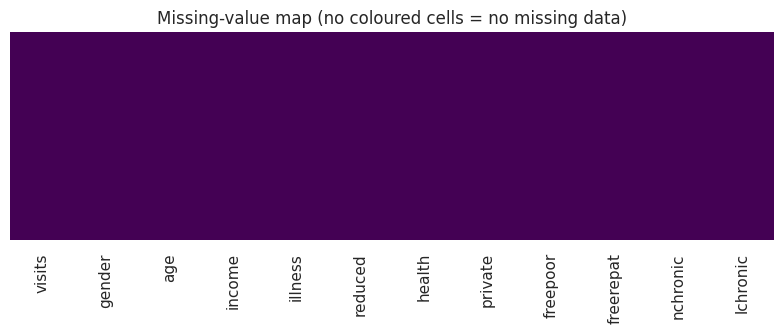

In [12]:
# Visualise missing values
plt.figure(figsize=(8, 3.5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing-value map (no coloured cells = no missing data)")
plt.tight_layout(); plt.show()

**Observation:** There are **no missing values** in any column, so no imputation is needed.

In [13]:
# Duplicate check
dup_mask = df.duplicated()
print("Duplicate rows:", dup_mask.sum(), f"({dup_mask.mean()*100:.1f}% of data)")

Duplicate rows: 1320 (25.4% of data)


**Important: should these duplicates be removed?** A standard checklist says "drop duplicates", but that is only correct when a duplicate means the *same record was entered twice*. Here there is no person ID, and `age` and `income` are stored as **banded midpoints** (only 12 distinct ages and 14 distinct incomes). So two different people can easily share identical values on all 12 columns. The next cells check what removing them would actually do.

In [14]:
dedup = df.drop_duplicates()
check = pd.DataFrame({
    "Rows": [len(df), len(dedup)],
    "Mean visits (2 wks)": [df["visits"].mean(), dedup["visits"].mean()],
    "% with >=1 visit": [(df["visits"] > 0).mean()*100, (dedup["visits"] > 0).mean()*100],
}, index=["Original (all rows)", "After drop_duplicates()"])
display(check)

dups = df[df.duplicated(keep=False)]
print(f"Share of duplicated rows that have ZERO visits: {(dups['visits'] == 0).mean()*100:.1f}%")
print(f"Share of ALL rows that have zero visits      : {(df['visits'] == 0).mean()*100:.1f}%")

,Rows,Mean visits (2 wks),% with >=1 visit
Original (all rows),5190,0.302,20.212
After drop_duplicates(),3870,0.389,25.581


Share of duplicated rows that have ZERO visits: 94.8%
Share of ALL rows that have zero visits      : 79.8%


**Cleaning decision, duplicates are KEPT.** About 95% of the duplicated rows are people with zero visits, and zero visits is also the most common outcome overall (about 80%). Healthy, low-use respondents with the same banded profile naturally look identical. Dropping them would remove 1,320 genuine respondents and **inflate the average visit rate from 0.30 to 0.39 (about +29%)**, which is a biased picture of healthcare use. Duplicates are only removed when we can show they are data-entry repeats, and this dataset gives no evidence of that.

In [15]:
# Convert to proper types
yn_cols = ["private", "freepoor", "freerepat", "nchronic", "lchronic"]
for c in yn_cols + ["gender"]:
    df[c] = df[c].astype("category")

# Derived features (documented, so interpretation is easy)
df["age_years"] = (df["age"] * 100).round().astype(int)              # age was stored as years/100
df["income_aud"] = (df["income"] * 10000).round(0)                    # income was stored in AUD 10,000 units
df["visited"] = (df["visits"] > 0).astype(int)                        # binary: any visit?
df["age_group"] = pd.cut(df["age_years"], bins=[0, 24, 34, 49, 64, 100],
                         labels=["15-24", "25-34", "35-49", "50-64", "65+"])
df["income_band"] = pd.cut(df["income"], bins=[-0.01, 0.2, 0.5, 0.9, 1.5],
                           labels=["Very low (<=2k)", "Low (2-5k)", "Middle (5-9k)", "High (9k+)"])
df["visit_cat"] = pd.cut(df["visits"], bins=[-1, 0, 1, 100], labels=["0 visits", "1 visit", "2+ visits"])
df["illness_group"] = pd.cut(df["illness"], bins=[-1, 0, 1, 2, 5], labels=["0", "1", "2", "3-5"])
df["insurance"] = np.select(
    [df["freepoor"] == "yes", df["freerepat"] == "yes", df["private"] == "yes"],
    ["Free (low income)", "Free (age/disability/veteran)", "Private"],
    default="Public only (no extra cover)")
df["chronic_status"] = np.select(
    [df["lchronic"] == "yes", df["nchronic"] == "yes"],
    ["Chronic - limiting", "Chronic - not limiting"], default="No chronic condition")
print("Shape after cleaning & feature engineering:", df.shape)
df[["age", "age_years", "income", "income_aud", "visits", "visited", "insurance", "chronic_status"]].head()

Shape after cleaning & feature engineering: (5190, 21)


,age,age_years,income,income_aud,visits,visited,insurance,chronic_status
0,0.190,19,0.550,"5,500.000",1,1,Private,No chronic condition
1,0.190,19,0.450,"4,500.000",1,1,Private,No chronic condition
2,0.190,19,0.900,"9,000.000",1,1,Public only (no extra cover),No chronic condition
3,0.190,19,0.150,"1,500.000",1,1,Public only (no extra cover),No chronic condition
4,0.190,19,0.450,"4,500.000",1,1,Public only (no extra cover),Chronic - not limiting


In [16]:
# Check the 'insurance' categories are mutually exclusive (a validity check on the source columns)
print(pd.crosstab(df["freepoor"], df["freerepat"], rownames=["freepoor"], colnames=["freerepat"]))
print(pd.crosstab(df["private"], [df["freepoor"], df["freerepat"]]))

freerepat    no   yes
freepoor             
no         3877  1091
yes         222     0
freepoor     no        yes
freerepat    no   yes   no
private                   
no         1579  1091  222
yes        2298     0    0


**Observation:** `freepoor` and `freerepat` are never "yes" together, and nobody with free government cover also has private cover. This confirms the insurance categories are mutually exclusive, so combining them into one `insurance` column is valid. The 12 `age` values and 14 `income` values confirm that both are banded, not exact.

## 6. Data Cleaning and Treatment: Outlier Check
`visits` has a maximum of 9 against a 75th percentile of 0. Check whether that is an error.

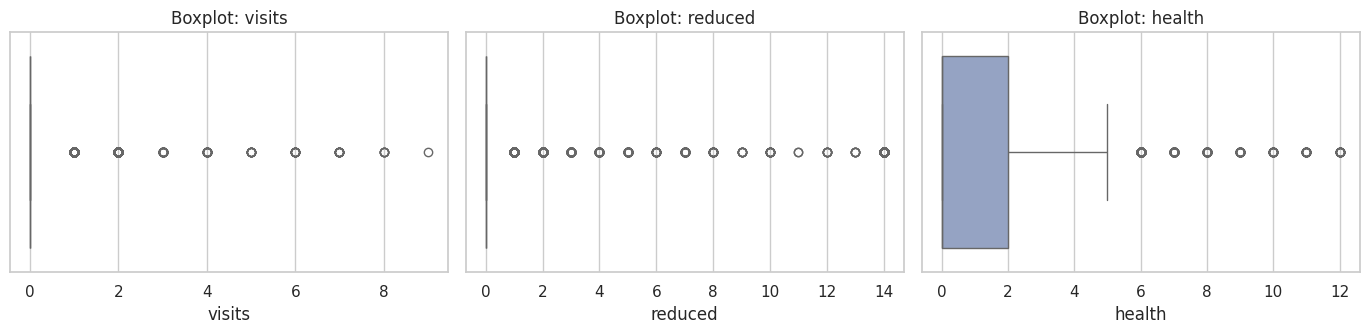

visits   IQR upper bound =   0.0 | rows above = 1049 | max = 9
reduced  IQR upper bound =   0.0 | rows above =  736 | max = 14
illness  IQR upper bound =   5.0 | rows above =    0 | max = 5
health   IQR upper bound =   5.0 | rows above =  303 | max = 12


In [17]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, c in zip(ax, ["visits", "reduced", "health"]):
    sns.boxplot(x=df[c], ax=a, color="#8da0cb"); a.set_title(f"Boxplot: {c}")
plt.tight_layout(); plt.show()

for c in ["visits", "reduced", "illness", "health"]:
    q1, q3 = df[c].quantile([.25, .75]); ub = q3 + 1.5*(q3-q1)
    print(f"{c:8s} IQR upper bound = {ub:5.1f} | rows above = {(df[c] > ub).sum():4d} | max = {df[c].max()}")

**Cleaning decision, outliers are KEPT.** The IQR rule flags every non-zero `visits` value because the IQR is 0. That is a limitation of the IQR rule on zero-heavy count data, not evidence of errors. A value of 9 visits in two weeks is plausible for someone with a serious condition, and all values fall in the valid range (visits 0-9, reduced 0-14, health 0-12, illness 0-5). These heavy users are exactly the people healthcare planners care about, so removing them would hide the key finding.

## 7. Feature / Variable Review

In [18]:
numerical_cols = ["visits", "age_years", "income_aud", "illness", "reduced", "health"]
categorical_cols = ["gender", "insurance", "chronic_status", "private", "freepoor", "freerepat", "nchronic", "lchronic"]
print("Numerical  :", numerical_cols)
print("Categorical:", categorical_cols)

pd.DataFrame({
    "Variable": ["visits", "age / age_years", "income / income_aud", "illness", "reduced", "health",
                 "gender", "private, freepoor, freerepat -> insurance", "nchronic, lchronic -> chronic_status"],
    "Type": ["Count (target)", "Discrete (12 age bands)", "Discrete (14 income bands)", "Count 0-5", "Count 0-14",
             "Score 0-12 (higher = worse)", "Binary", "Binary flags -> 4-way category", "Binary flags -> 3-way category"],
    "Role": ["Outcome: doctor visits in 2 weeks", "Demographic", "Socio-economic", "Health need", "Health need (severity)",
             "Health need (mental/general)", "Demographic", "Access / cost barrier", "Health need (long-term)"]})

Numerical  : ['visits', 'age_years', 'income_aud', 'illness', 'reduced', 'health']
Categorical: ['gender', 'insurance', 'chronic_status', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']


,Variable,Type,Role
0,visits,Count (target),Outcome: doctor visits in 2 weeks
1,age / age_years,Discrete (12 age bands),Demographic
2,income / income_aud,Discrete (14 income bands),Socio-economic
3,illness,Count 0-5,Health need
4,reduced,Count 0-14,Health need (severity)
5,health,Score 0-12 (higher = worse),Health need (mental/general)
6,gender,Binary,Demographic
7,"private, freepoor, freerepat -> insurance",Binary flags -> 4-way category,Access / cost barrier
8,"nchronic, lchronic -> chronic_status",Binary flags -> 3-way category,Health need (long-term)


## 8. Descriptive Statistics

In [19]:
desc = df[numerical_cols].describe().T
desc["skew"] = df[numerical_cols].skew()
desc["variance"] = df[numerical_cols].var()
desc

,count,mean,std,min,25%,50%,75%,max,skew,variance
visits,"5,190.000",0.302,0.798,0.000,0.000,0.000,0.000,9.000,4.743,0.637
age_years,"5,190.000",40.639,20.478,19.000,22.000,32.000,62.000,72.000,0.421,419.356
income_aud,"5,190.000","5,831.599","3,689.067",0.000,"2,500.000","5,500.000","9,000.000","15,000.000",0.734,"13,609,215.210"
illness,"5,190.000",1.432,1.384,0.000,0.000,1.000,2.000,5.000,0.940,1.916
reduced,"5,190.000",0.862,2.888,0.000,0.000,0.000,0.000,14.000,3.828,8.338
health,"5,190.000",1.218,2.124,0.000,0.000,0.000,2.000,12.000,2.400,4.513


In [20]:
print("Mean of visits    :", round(df['visits'].mean(), 3))
print("Variance of visits:", round(df['visits'].var(), 3))
print("Variance / mean   :", round(df['visits'].var() / df['visits'].mean(), 2), " (a Poisson distribution would give 1.0)")
print("Zero-visit share  :", f"{(df['visits']==0).mean()*100:.1f}%")

Mean of visits    : 0.302
Variance of visits: 0.637
Variance / mean   : 2.11  (a Poisson distribution would give 1.0)
Zero-visit share  : 79.8%


**Note:** The variance of `visits` (0.64) is about twice its mean (0.30). This is called **overdispersion** and matters later: a plain Poisson model or an ANOVA assumes the wrong spread. `visits` is also heavily right-skewed (about 80% zeros), so means alone are misleading and we report **visit rate** (% with at least one visit) alongside mean visits.

In [21]:
# Group-wise summary tables (mean visits and % who visited)
def group_summary(col):
    g = df.groupby(col, observed=True).agg(
        People=("visits", "size"),
        Mean_visits=("visits", "mean"),
        Pct_visited=("visited", lambda s: s.mean()*100),
        Avg_illness=("illness", "mean"),
        Avg_reduced_days=("reduced", "mean"))
    return g.round(3)

for c in ["gender", "age_group", "insurance", "chronic_status"]:
    print(f"\n--- By {c} ---")
    display(group_summary(c))


--- By gender ---


,People,Mean_visits,Pct_visited,Avg_illness,Avg_reduced_days
gender,,,,,
female,2702,0.362,24.426,1.611,0.976
male,2488,0.236,15.635,1.238,0.738



--- By age_group ---


,People,Mean_visits,Pct_visited,Avg_illness,Avg_reduced_days
age_group,,,,,
15-24,1965,0.206,14.656,1.216,0.577
25-34,824,0.252,16.626,1.169,0.727
35-49,453,0.276,17.219,1.276,0.929
50-64,811,0.386,25.031,1.683,1.059
65+,1137,0.454,30.167,1.879,1.284



--- By insurance ---


,People,Mean_visits,Pct_visited,Avg_illness,Avg_reduced_days
insurance,,,,,
Free (age/disability/veteran),1091,0.467,31.622,1.974,1.331
Free (low income),222,0.158,9.009,1.261,0.770
Private,2298,0.295,20.017,1.359,0.765
Public only (no extra cover),1579,0.218,14.186,1.187,0.692



--- By chronic_status ---


,People,Mean_visits,Pct_visited,Avg_illness,Avg_reduced_days
chronic_status,,,,,
Chronic - limiting,605,0.603,35.041,2.273,2.583
Chronic - not limiting,2092,0.346,23.662,1.845,0.855
No chronic condition,2493,0.192,13.718,0.881,0.450


## 9. Univariate Analysis
One variable at a time.

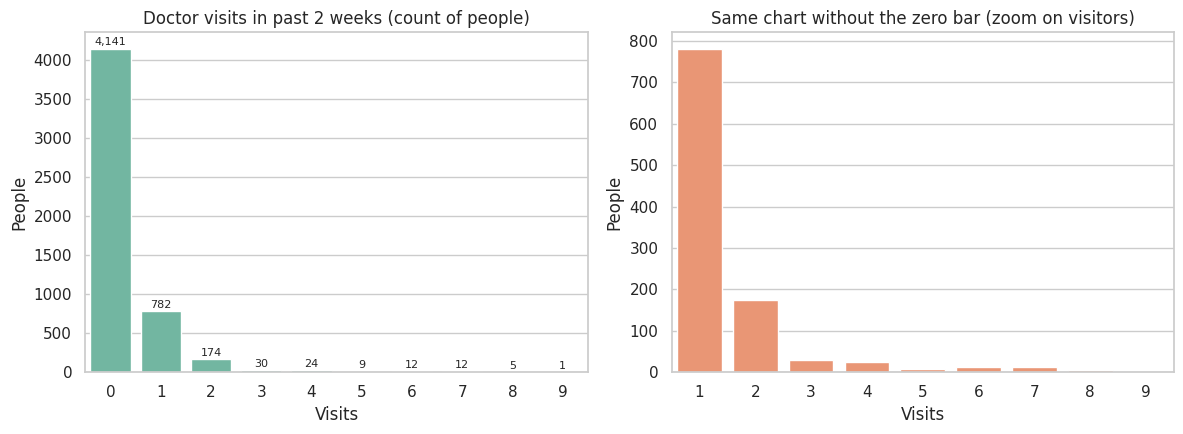

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
vc = df["visits"].value_counts().sort_index()
sns.barplot(x=vc.index, y=vc.values, ax=ax[0], color="#66c2a5")
for i, v in enumerate(vc.values): ax[0].text(i, v+40, f"{v:,}", ha="center", fontsize=8)
ax[0].set_title("Doctor visits in past 2 weeks (count of people)"); ax[0].set_xlabel("Visits"); ax[0].set_ylabel("People")
sns.barplot(x=vc.index[1:], y=vc.values[1:], ax=ax[1], color="#fc8d62")
ax[1].set_title("Same chart without the zero bar (zoom on visitors)"); ax[1].set_xlabel("Visits"); ax[1].set_ylabel("People")
plt.tight_layout(); plt.show()

**Note:** 4,141 of 5,190 people (79.8%) had no doctor visit. Among the 1,049 who did, most had exactly one (782). Only 93 people (1.8%) had 3 or more visits, yet the next cell shows they generate far more than their share of total visits.

In [23]:
# Share of total visits by visit frequency band (concentration of demand)
tot = df["visits"].sum()
share = df.groupby("visit_cat", observed=True)["visits"].sum() / tot * 100
print(share.round(1).to_string())
heavy = (df["visits"] >= 3)
print(f"\nPeople with 3+ visits: {heavy.sum()} ({heavy.mean()*100:.1f}% of sample) account for {df.loc[heavy,'visits'].sum()/tot*100:.1f}% of all visits")

visit_cat
0 visits     0.000
1 visit     49.900
2+ visits   50.100

People with 3+ visits: 93 (1.8% of sample) account for 27.8% of all visits


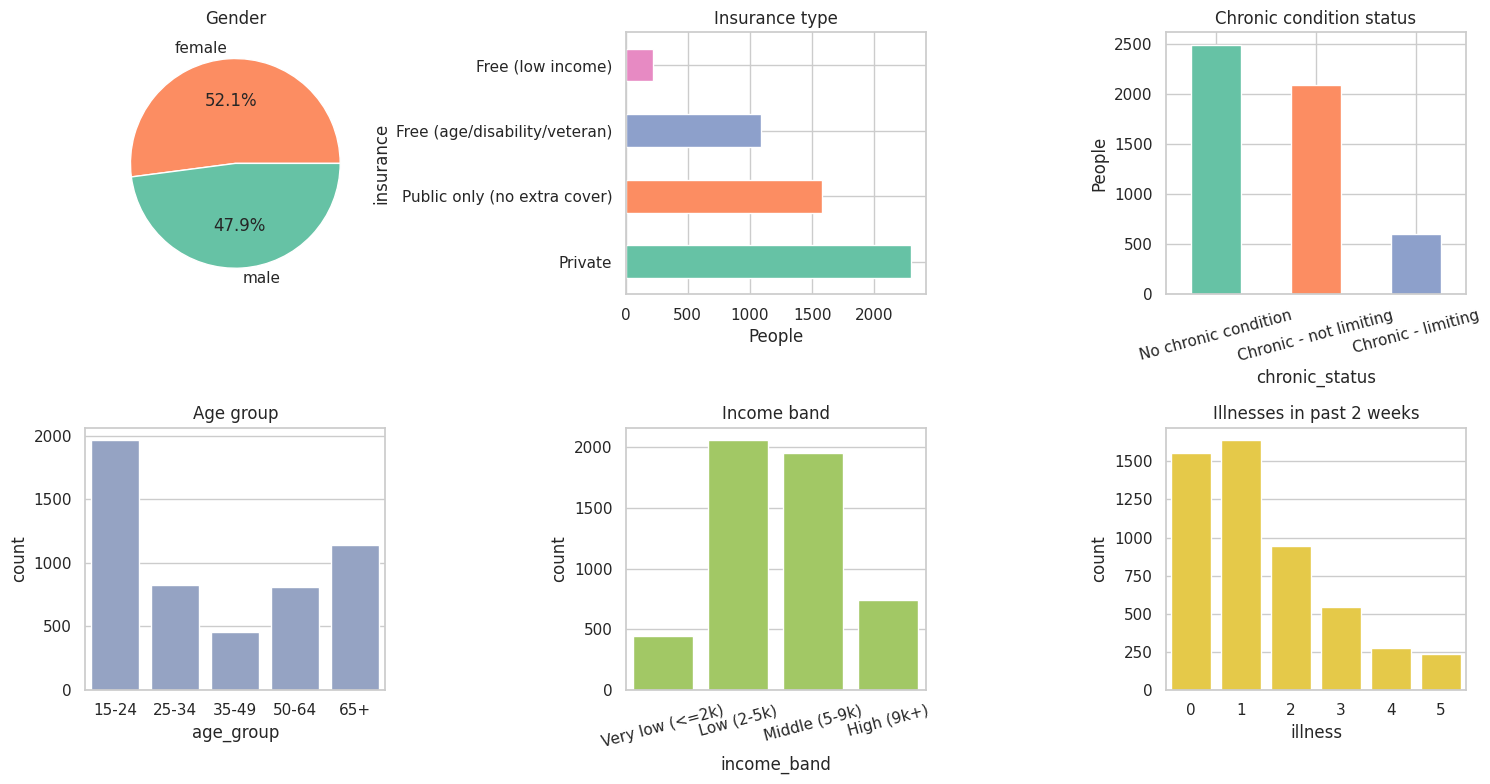

In [24]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
df["gender"].value_counts().plot.pie(ax=ax[0,0], autopct="%1.1f%%", colors=["#fc8d62", "#66c2a5"], ylabel="")
ax[0,0].set_title("Gender")
df["insurance"].value_counts().plot.barh(ax=ax[0,1], color=sns.color_palette("Set2"))
ax[0,1].set_title("Insurance type"); ax[0,1].set_xlabel("People")
df["chronic_status"].value_counts().plot.bar(ax=ax[0,2], color=sns.color_palette("Set2"), rot=15)
ax[0,2].set_title("Chronic condition status"); ax[0,2].set_ylabel("People")
sns.countplot(data=df, x="age_group", ax=ax[1,0], color="#8da0cb"); ax[1,0].set_title("Age group")
sns.countplot(data=df, x="income_band", ax=ax[1,1], color="#a6d854"); ax[1,1].set_title("Income band"); ax[1,1].tick_params(axis="x", rotation=15)
sns.countplot(data=df, x="illness", ax=ax[1,2], color="#ffd92f"); ax[1,2].set_title("Illnesses in past 2 weeks")
plt.tight_layout(); plt.show()

**Note:** The sample is **not** a mirror of the population. 15-24 year-olds and 65+ are heavily represented, consistent with the survey over-sampling the young and old. About 21% have free "old-age/disability/veteran" cover but only 4% have free low-income cover. These are sample facts to remember before generalising.

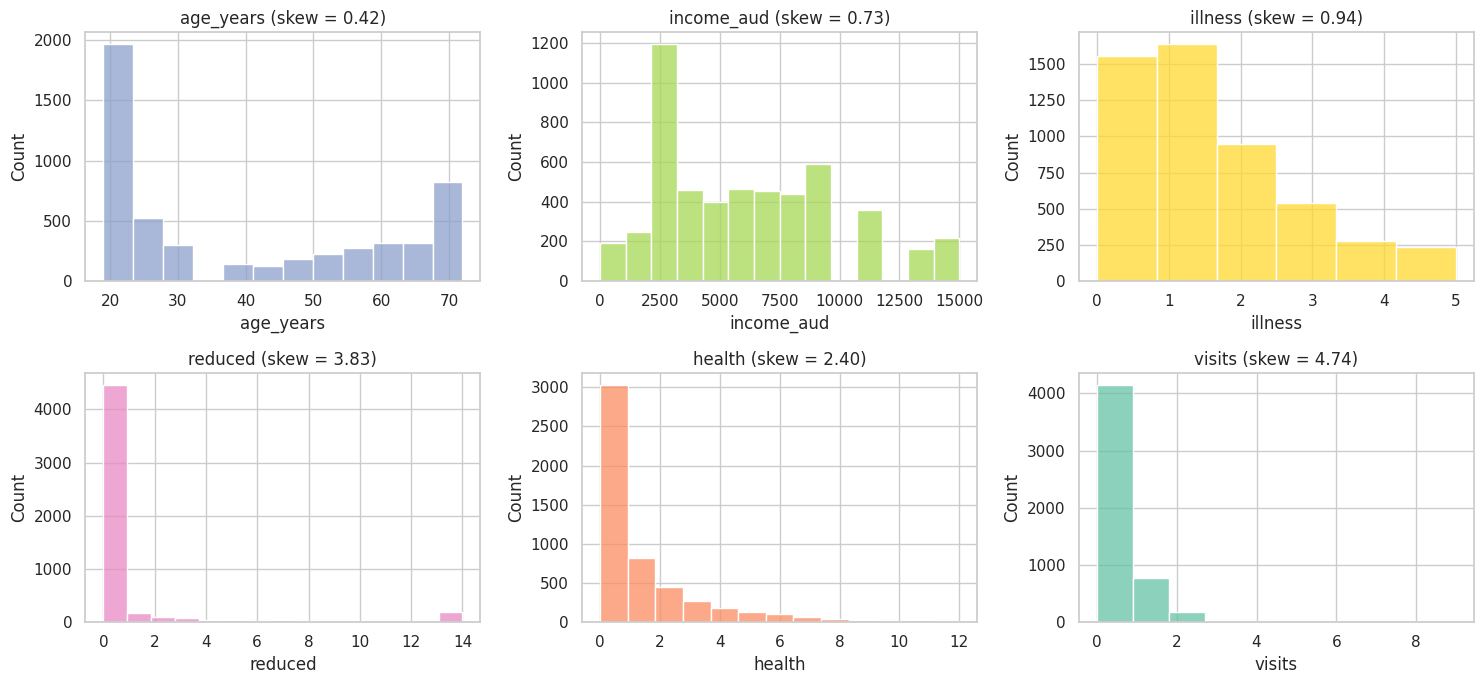

In [25]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, c, col in zip(ax.ravel(), ["age_years", "income_aud", "illness", "reduced", "health", "visits"],
                     ["#8da0cb", "#a6d854", "#ffd92f", "#e78ac3", "#fc8d62", "#66c2a5"]):
    sns.histplot(df[c], bins=min(30, df[c].nunique()), ax=a, color=col, kde=False)
    a.set_title(f"{c} (skew = {df[c].skew():.2f})")
plt.tight_layout(); plt.show()

**Note:** `reduced`, `visits` and `illness` pile up at zero with long right tails. `age_years` is U-shaped (many young and many 70+ respondents) because of the sampling design. `income_aud` clusters in lower bands and has a spike at the top-code (AUD 15,000).

## 10. Bivariate Analysis
Relationship of visits with each factor.

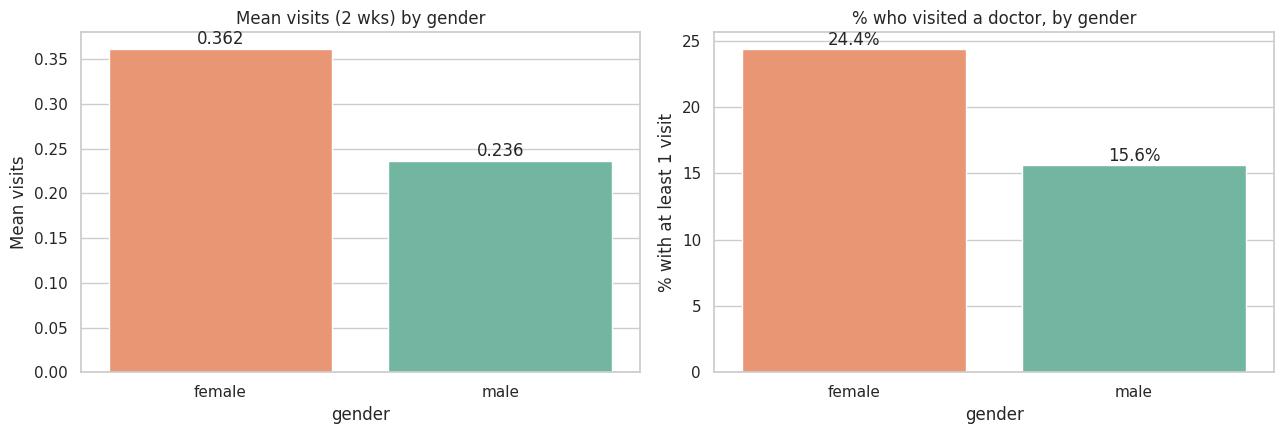

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
g = df.groupby("gender", observed=True).agg(mean=("visits", "mean"), pct=("visited", "mean"))
sns.barplot(x=g.index, y=g["mean"], ax=ax[0], palette=["#fc8d62", "#66c2a5"])
ax[0].set_title("Mean visits (2 wks) by gender"); ax[0].set_ylabel("Mean visits")
for i, v in enumerate(g["mean"]): ax[0].text(i, v+0.005, f"{v:.3f}", ha="center")
sns.barplot(x=g.index, y=g["pct"]*100, ax=ax[1], palette=["#fc8d62", "#66c2a5"])
ax[1].set_title("% who visited a doctor, by gender"); ax[1].set_ylabel("% with at least 1 visit")
for i, v in enumerate(g["pct"]*100): ax[1].text(i, v+0.3, f"{v:.1f}%", ha="center")
plt.tight_layout(); plt.show()

**Note:** Females visit more often (0.36 vs 0.24 mean visits; 24.4% vs 15.6% had at least one visit). Whether this is statistically solid is tested in Section 13.

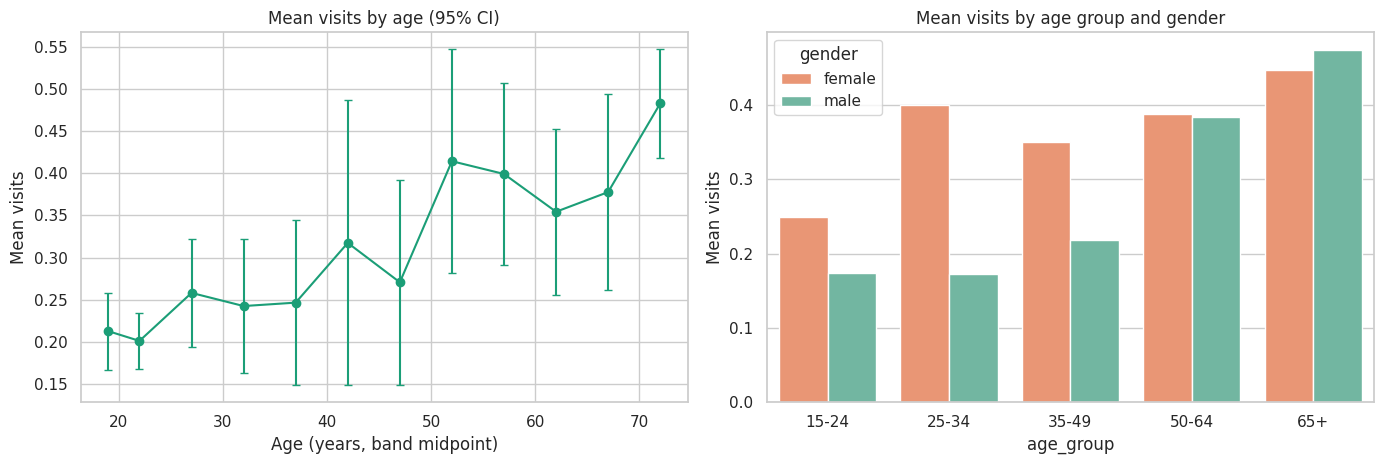

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
a = df.groupby("age_years", observed=True)["visits"].agg(["mean", "sem"]).reset_index()
ax[0].errorbar(a["age_years"], a["mean"], yerr=1.96*a["sem"], fmt="-o", color="#1b9e77", capsize=3)
ax[0].set_title("Mean visits by age (95% CI)"); ax[0].set_xlabel("Age (years, band midpoint)"); ax[0].set_ylabel("Mean visits")
a2 = df.groupby(["age_group", "gender"], observed=True)["visits"].mean().reset_index()
sns.barplot(data=a2, x="age_group", y="visits", hue="gender", ax=ax[1], palette=["#fc8d62", "#66c2a5"])
ax[1].set_title("Mean visits by age group and gender"); ax[1].set_ylabel("Mean visits")
plt.tight_layout(); plt.show()

**Note:** Visits rise with age, from about 0.2 for under-25s to about 0.48 for those 70+. The gender gap is clearest between ages 15 and 49 (e.g. 25-34: 0.40 female vs 0.17 male) and disappears from 50 upward, where males are equal or slightly higher. Note the wide error bars in the middle age bands, where the sample is small (roughly 125-320 people per band).

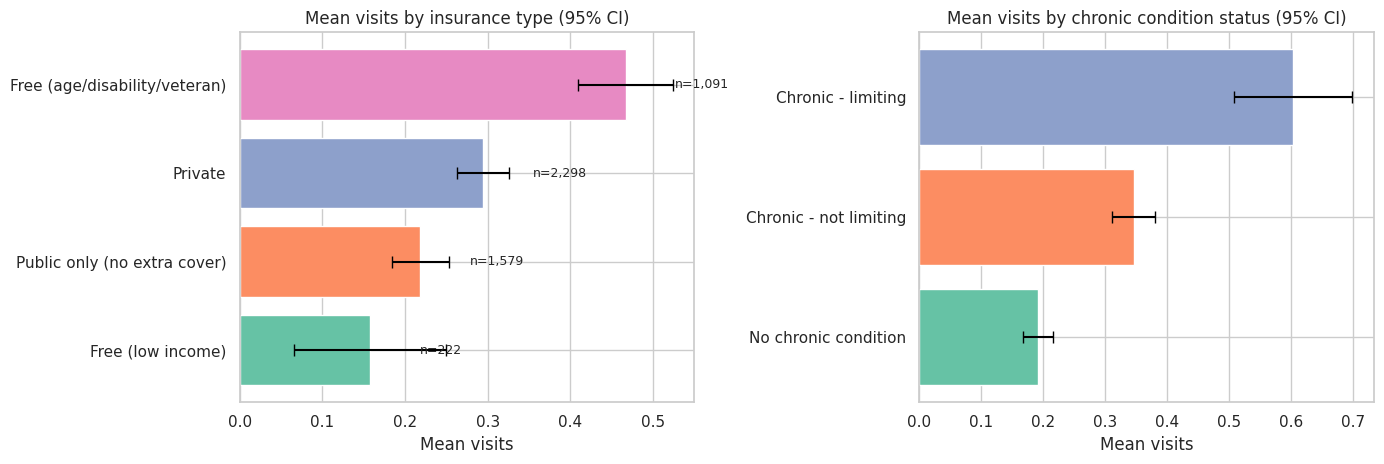

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ins = df.groupby("insurance")["visits"].agg(["mean", "sem", "size"]).sort_values("mean")
ax[0].barh(ins.index, ins["mean"], xerr=1.96*ins["sem"], color=sns.color_palette("Set2", 4), capsize=4)
ax[0].set_title("Mean visits by insurance type (95% CI)"); ax[0].set_xlabel("Mean visits")
for i, (m, n) in enumerate(zip(ins["mean"], ins["size"])): ax[0].text(m+0.06, i, f"n={n:,}", va="center", fontsize=9)
ch = df.groupby("chronic_status")["visits"].agg(["mean", "sem"]).sort_values("mean")
ax[1].barh(ch.index, ch["mean"], xerr=1.96*ch["sem"], color=sns.color_palette("Set2", 3), capsize=4)
ax[1].set_title("Mean visits by chronic condition status (95% CI)"); ax[1].set_xlabel("Mean visits")
plt.tight_layout(); plt.show()

**Note:** The free "age/disability/veteran" group has the highest visits (0.47), private holders 0.30, public-only 0.22, and the free "low-income" group the lowest (0.16, but only 222 people). Chronic conditions *that limit activity* go with about 3.1x the visits of people with no chronic condition (0.60 vs 0.19). These are raw differences only: the groups also differ a lot in age and health (the free age/disability group averages about 65 years old versus about 28 for public-only), which Sections 11 and 14 examine.

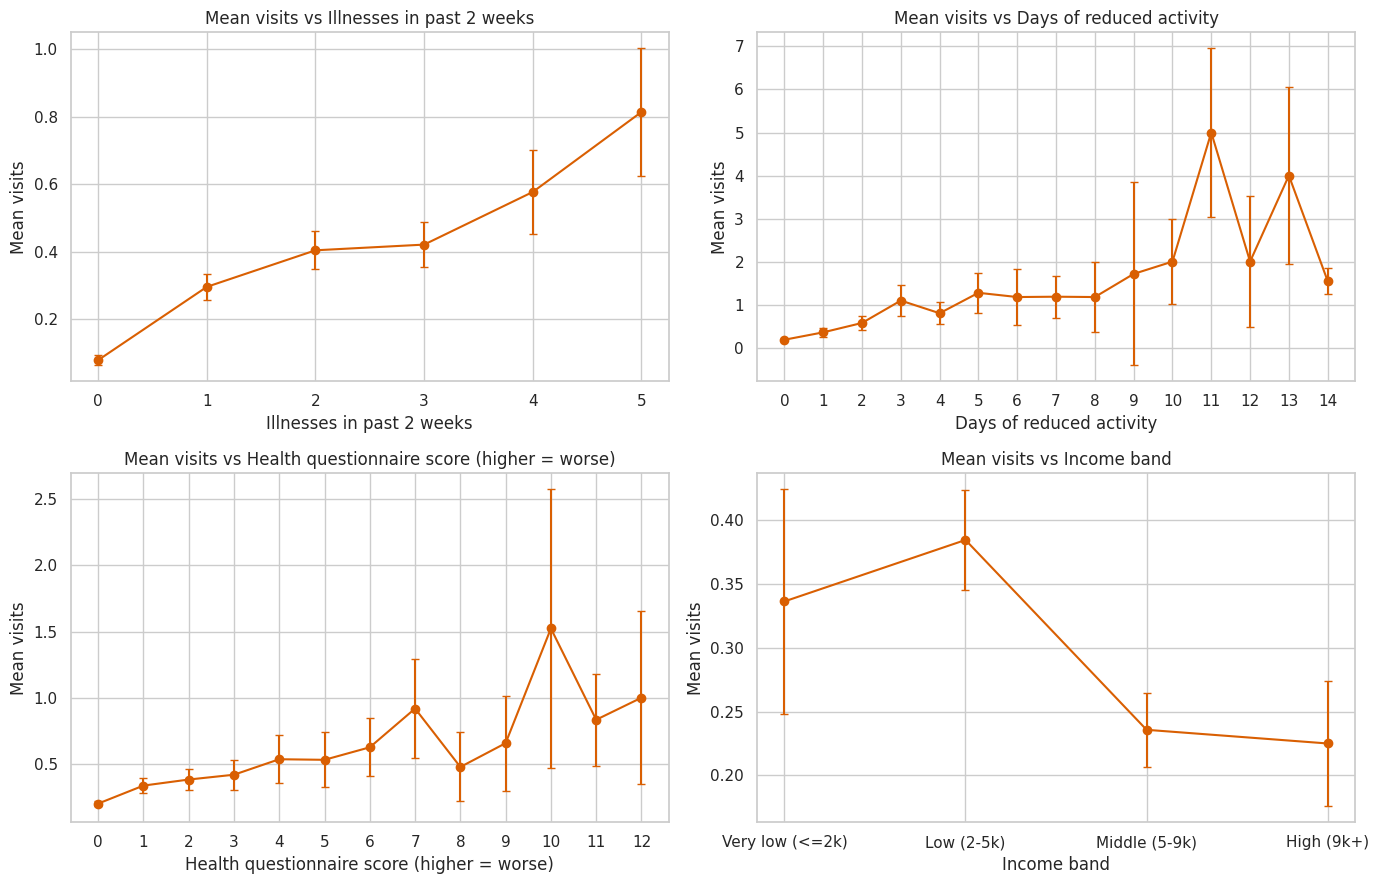

In [29]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for a, c, t in zip(ax.ravel(), ["illness", "reduced", "health", "income_band"],
                   ["Illnesses in past 2 weeks", "Days of reduced activity", "Health questionnaire score (higher = worse)", "Income band"]):
    d = df.groupby(c, observed=True)["visits"].agg(["mean", "sem", "size"]).reset_index()
    a.errorbar(d[c].astype(str), d["mean"], yerr=1.96*d["sem"], fmt="-o", color="#d95f02", capsize=3)
    a.set_title(f"Mean visits vs {t}"); a.set_xlabel(t); a.set_ylabel("Mean visits")
plt.tight_layout(); plt.show()

**Note:** Mean visits climb steadily with illness count (0.08 at zero illnesses to 0.69 at 3-5), with days of reduced activity, and with the health score. Income is not a clean trend: visits peak in the low-income bands (0.34-0.38) and are lowest in the top two bands (0.22-0.24). Health need looks like the strongest signal, with income weaker.

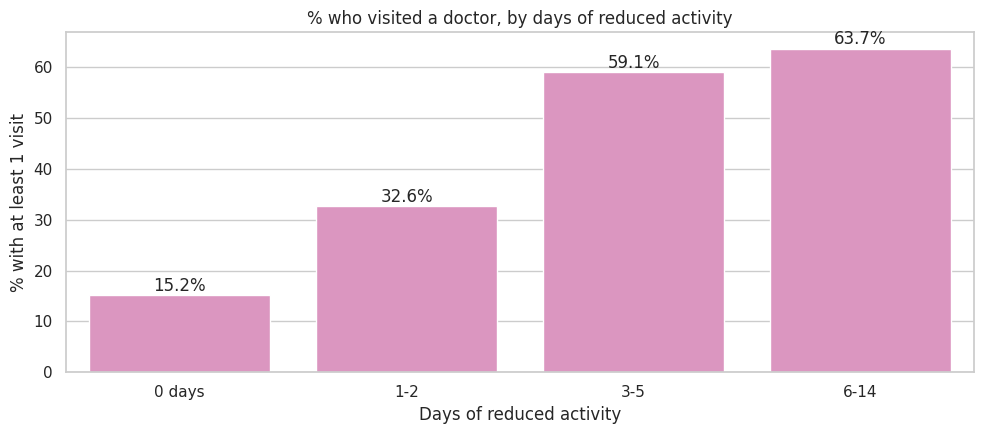

In [30]:
# Does reduced activity -> more visits? Boxen/strip view for the discrete counts
plt.figure(figsize=(10, 4.5))
rb = pd.cut(df["reduced"], bins=[-1, 0, 2, 5, 14], labels=["0 days", "1-2", "3-5", "6-14"])
d = df.groupby(rb, observed=True)["visited"].mean()*100
sns.barplot(x=d.index, y=d.values, color="#e78ac3")
for i, v in enumerate(d.values): plt.text(i, v+0.8, f"{v:.1f}%", ha="center")
plt.title("% who visited a doctor, by days of reduced activity"); plt.xlabel("Days of reduced activity"); plt.ylabel("% with at least 1 visit")
plt.tight_layout(); plt.show()

## 11. Multivariate Analysis

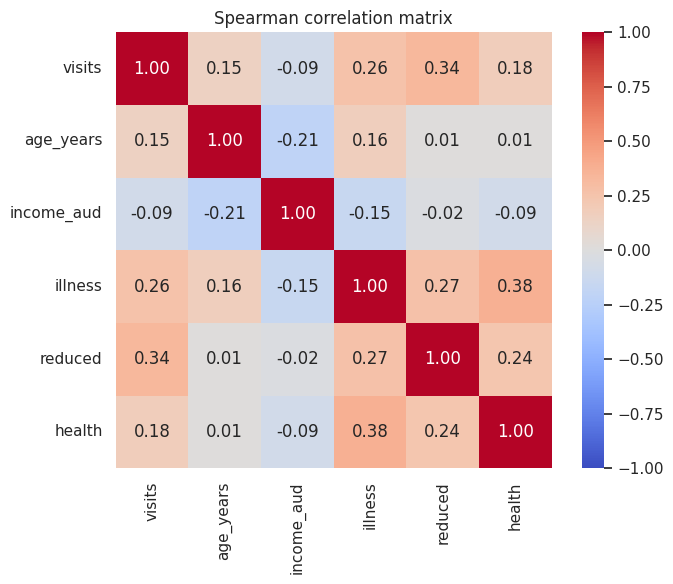

Correlation of each variable with visits:
reduced       0.336
illness       0.263
health        0.178
age_years     0.148
income_aud   -0.093


In [31]:
# Correlation heatmap (Spearman is used because the variables are skewed counts)
corr_cols = ["visits", "age_years", "income_aud", "illness", "reduced", "health"]
corr = df[corr_cols].corr(method="spearman")
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Spearman correlation matrix")
plt.tight_layout(); plt.show()
print("Correlation of each variable with visits:")
print(corr["visits"].drop("visits").sort_values(ascending=False).round(3).to_string())

**Note:** `reduced` (0.34) and `illness` (0.26) have the strongest links with visits, then `health` (0.18) and `age` (0.15). Income is weakly negative (-0.09). All correlations are modest, so no single variable explains visits on its own. `illness` and `health` are also correlated with each other (0.38), meaning they partly overlap.

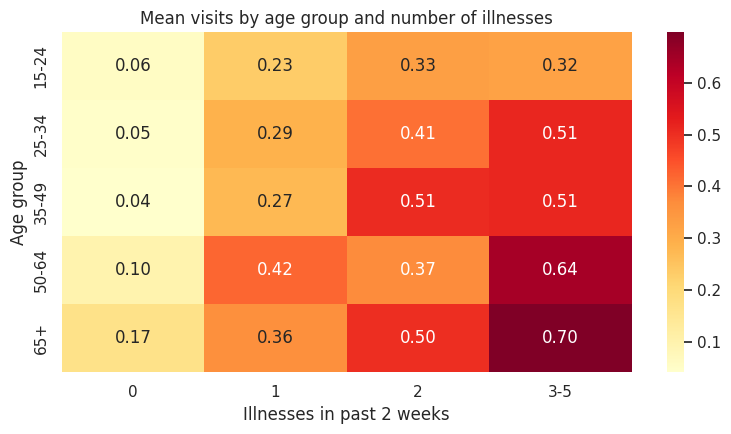

In [32]:
# Age group x illness: how need and age combine
pt = df.pivot_table(index="age_group", columns="illness_group", values="visits", aggfunc="mean", observed=True)
plt.figure(figsize=(8, 4.5))
sns.heatmap(pt, annot=True, fmt=".2f", cmap="YlOrRd")
plt.title("Mean visits by age group and number of illnesses")
plt.xlabel("Illnesses in past 2 weeks"); plt.ylabel("Age group")
plt.tight_layout(); plt.show()

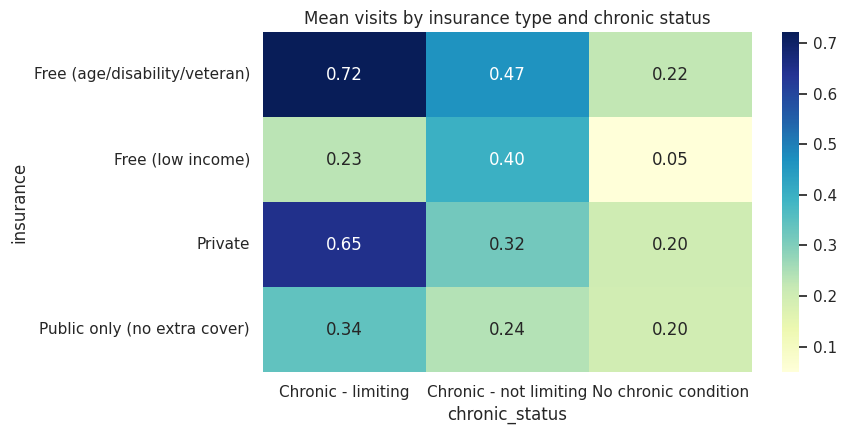

chronic_status,Chronic - limiting,Chronic - not limiting,No chronic condition
insurance,,,
Free (age/disability/veteran),237,608,246
Free (low income),26,55,141
Private,231,969,1098
Public only (no extra cover),111,460,1008


In [33]:
# Insurance x chronic status
pt2 = df.pivot_table(index="insurance", columns="chronic_status", values="visits", aggfunc="mean")
cnt = df.pivot_table(index="insurance", columns="chronic_status", values="visits", aggfunc="size")
plt.figure(figsize=(9, 4.5))
sns.heatmap(pt2, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Mean visits by insurance type and chronic status")
plt.tight_layout(); plt.show()
cnt

**Note:** Chronic status alone does *not* erase the insurance gaps: among people with a limiting chronic condition, the free age/disability and private groups still average 0.72 and 0.65 visits versus 0.34 for public-only. These groups also differ in age (free age/disability averages about 65 years) and current illness, so a single cross-tab cannot separate the effects. Section 14 does this with an adjusted model.

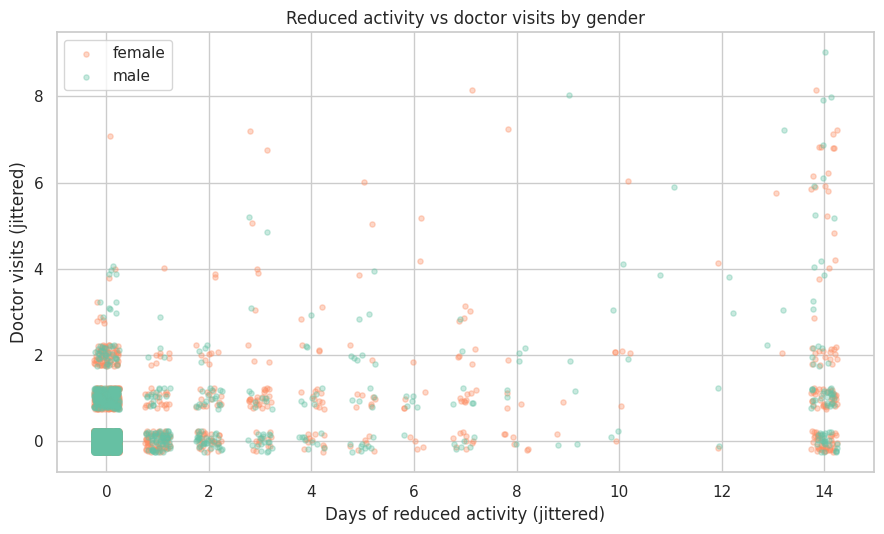

In [34]:
# Illness vs visits, coloured by gender (with jitter, since both are small integers)
rng = np.random.default_rng(42)
plt.figure(figsize=(9, 5.5))
for g, col in zip(["female", "male"], ["#fc8d62", "#66c2a5"]):
    s = df[df["gender"] == g]
    plt.scatter(s["reduced"] + rng.uniform(-.25, .25, len(s)), s["visits"] + rng.uniform(-.25, .25, len(s)),
                alpha=.35, s=14, c=col, label=g)
plt.xlabel("Days of reduced activity (jittered)"); plt.ylabel("Doctor visits (jittered)")
plt.title("Reduced activity vs doctor visits by gender"); plt.legend(); plt.tight_layout(); plt.show()

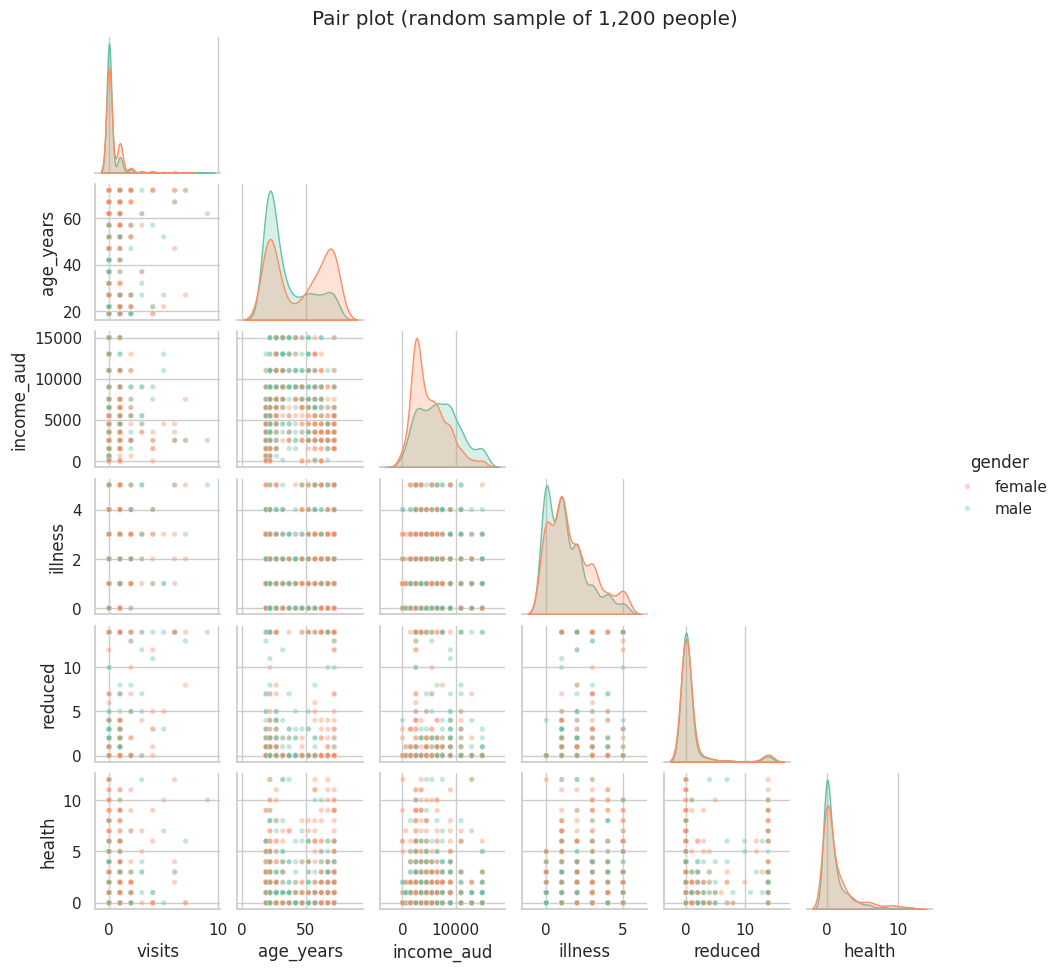

In [35]:
# Pair plot on a random sample (a sample is used to keep plotting fast and readable)
sns.pairplot(df.sample(1200, random_state=1)[["visits", "age_years", "income_aud", "illness", "reduced", "health", "gender"]],
             hue="gender", palette=["#fc8d62", "#66c2a5"], plot_kws={"alpha": .4, "s": 15}, corner=True, height=1.6)
plt.suptitle("Pair plot (random sample of 1,200 people)", y=1.01); plt.show()

## 12. Outlier Analysis

In [36]:
rows = []
for c in ["visits", "reduced", "illness", "health", "income_aud", "age_years"]:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    ub, lb = q3 + 1.5*iqr, q1 - 1.5*iqr
    rows.append([c, q1, q3, lb, ub, ((df[c] > ub) | (df[c] < lb)).sum()])
pd.DataFrame(rows, columns=["Column", "Q1", "Q3", "Lower fence", "Upper fence", "Rows outside"])

,Column,Q1,Q3,Lower fence,Upper fence,Rows outside
0,visits,0.000,0.000,0.000,0.000,1049
1,reduced,0.000,0.000,0.000,0.000,736
2,illness,0.000,2.000,-3.000,5.000,0
3,health,0.000,2.000,-3.000,5.000,303
4,income_aud,"2,500.000","9,000.000","-7,250.000","18,750.000",0
5,age_years,22.000,62.000,-38.000,122.000,0


In [37]:
# Who are the heavy users? (5+ visits in two weeks)
heavy = df[df["visits"] >= 5]
print("Heavy users (5+ visits):", len(heavy), f"({len(heavy)/len(df)*100:.2f}% of sample)")
comparison = pd.DataFrame({
    "Heavy users (5+ visits)": heavy[["age_years", "illness", "reduced", "health", "income_aud"]].mean(),
    "Everyone else": df[df["visits"] < 5][["age_years", "illness", "reduced", "health", "income_aud"]].mean()})
display(comparison)
print("% with limiting chronic condition - heavy users:", round((heavy["lchronic"] == "yes").mean()*100, 1),
      "| others:", round((df[df['visits'] < 5]["lchronic"] == "yes").mean()*100, 1))

Heavy users (5+ visits): 39 (0.75% of sample)


,Heavy users (5+ visits),Everyone else
age_years,52.103,40.552
illness,2.590,1.423
reduced,10.872,0.786
health,3.385,1.201
income_aud,"4,682.051","5,840.303"


% with limiting chronic condition - heavy users: 33.3 | others: 11.5


**Note:** The 5+ visit group is small (39 people, 0.75%) but is distinctly sicker: about 10.9 days of reduced activity versus 0.8 for everyone else, and 33% with a limiting chronic condition versus 11.5%. These are real high-need patients, not data errors, which supports the decision to keep them.

## 13. Statistical Testing
Because `visits` is a **skewed count** with many zeros, the reference-style ANOVA/t-test on raw means is not the best tool. We use non-parametric tests for group differences, a chi-square test for the visited/not-visited outcome, and finally a **count regression** that adjusts for all factors at once.

In [38]:
# 1) Gender: Mann-Whitney U (differences in distribution) and chi-square on visited yes/no
f = df.loc[df["gender"] == "female", "visits"]; m = df.loc[df["gender"] == "male", "visits"]
u, p_u = stats.mannwhitneyu(f, m, alternative="two-sided")
chi2, p_c, _, _ = stats.chi2_contingency(pd.crosstab(df["gender"], df["visited"]))
print(f"Mann-Whitney U (visits, female vs male): p = {p_u:.2e}")
print(f"Chi-square (visited yes/no vs gender)  : p = {p_c:.2e}")

Mann-Whitney U (visits, female vs male): p = 6.34e-15
Chi-square (visited yes/no vs gender)  : p = 4.35e-15


In [39]:
# 2) Do visits differ by insurance type and chronic status? Kruskal-Wallis (non-parametric ANOVA)
for col in ["insurance", "chronic_status", "age_group", "income_band"]:
    groups = [g["visits"].values for _, g in df.groupby(col, observed=True)]
    h, p = stats.kruskal(*groups)
    print(f"Kruskal-Wallis visits ~ {col:15s}: H = {h:7.1f}, p = {p:.2e}")

Kruskal-Wallis visits ~ insurance      : H =   138.1, p = 9.89e-30
Kruskal-Wallis visits ~ chronic_status : H =   170.6, p = 9.03e-38
Kruskal-Wallis visits ~ age_group      : H =   126.5, p = 2.19e-26
Kruskal-Wallis visits ~ income_band    : H =    59.2, p = 8.74e-13


In [40]:
# 3) Effect sizes with bootstrap confidence intervals (a p-value alone does not say HOW BIG the difference is)
def boot_ratio(a, b, n=3000, seed=0):
    r = np.random.default_rng(seed)
    out = [r.choice(a, len(a)).mean() / r.choice(b, len(b)).mean() for _ in range(n)]
    return np.mean(a)/np.mean(b), np.percentile(out, [2.5, 97.5])

tests = {
    "Female vs Male": (f.values, m.values),
    "Limiting chronic vs none": (df.loc[df.lchronic == "yes", "visits"].values, df.loc[df.lchronic == "no", "visits"].values),
    "Private vs no private": (df.loc[df.private == "yes", "visits"].values, df.loc[df.private == "no", "visits"].values),
    "Free (low income) vs rest": (df.loc[df.freepoor == "yes", "visits"].values, df.loc[df.freepoor == "no", "visits"].values),
}
res = []
for k, (a, b) in tests.items():
    r, ci = boot_ratio(a, b)
    res.append([k, r, ci[0], ci[1]])
pd.DataFrame(res, columns=["Comparison", "Ratio of mean visits", "CI low (95%)", "CI high (95%)"])

,Comparison,Ratio of mean visits,CI low (95%),CI high (95%)
0,Female vs Male,1.532,1.319,1.796
1,Limiting chronic vs none,2.303,1.920,2.743
2,Private vs no private,0.958,0.829,1.102
3,Free (low income) vs rest,0.512,0.249,0.874


**Note:** Gender (ratio about 1.5), limiting chronic condition (about 2.3) and age group show clear differences. "Private vs no private" is near 1.0 (CI includes 1), but be careful: the "no private" group mixes public-only people with the heavy-using free age/disability group, so this comparison hides the private vs public-only gap that Section 14 examines. The free (low-income) group has about half the visits (ratio 0.51), though with only 222 people the interval is wide (0.25 to 0.87).

In [41]:
# 4) Count regression: adjusts every factor at the same time.
# Poisson first, then check overdispersion, then Negative Binomial.
formula = ("visits ~ C(gender) + age_years + income + illness + reduced + health"
           " + C(private) + C(freepoor) + C(freerepat) + C(nchronic) + C(lchronic)")
poisson = smf.glm(formula, data=df, family=sm.families.Poisson()).fit()
disp = poisson.pearson_chi2 / poisson.df_resid
print(f"Poisson dispersion (Pearson chi2 / df) = {disp:.2f}  -> values above 1 mean overdispersion")

nb = smf.glm(formula, data=df, family=sm.families.NegativeBinomial(alpha=0.5)).fit()
# estimate alpha by a quick profile search on log-likelihood
best = max(np.arange(0.1, 2.01, 0.1),
           key=lambda a: smf.glm(formula, data=df, family=sm.families.NegativeBinomial(alpha=a)).fit().llf)
nb = smf.glm(formula, data=df, family=sm.families.NegativeBinomial(alpha=best)).fit()
print(f"Negative Binomial alpha (dispersion) chosen: {best:.1f}")
print(f"AIC  Poisson: {poisson.aic:,.1f}  |  Negative Binomial: {nb.aic:,.1f}  (lower is better)")

Poisson dispersion (Pearson chi2 / df) = 1.33  -> values above 1 mean overdispersion
Negative Binomial alpha (dispersion) chosen: 1.1
AIC  Poisson: 6,735.7  |  Negative Binomial: 6,421.7  (lower is better)


,IRR,CI low,CI high,p-value
illness,1.240,1.184,1.299,0.000
lchronic: yes,1.202,0.981,1.472,0.076
freerepat: yes,1.158,0.922,1.455,0.207
reduced,1.155,1.138,1.172,0.000
private: yes,1.124,0.950,1.330,0.174
nchronic: yes,1.103,0.944,1.288,0.218
health,1.038,1.011,1.067,0.006
age_years,1.003,0.999,1.007,0.112
income,0.855,0.697,1.049,0.134
gender: male,0.805,0.702,0.923,0.002


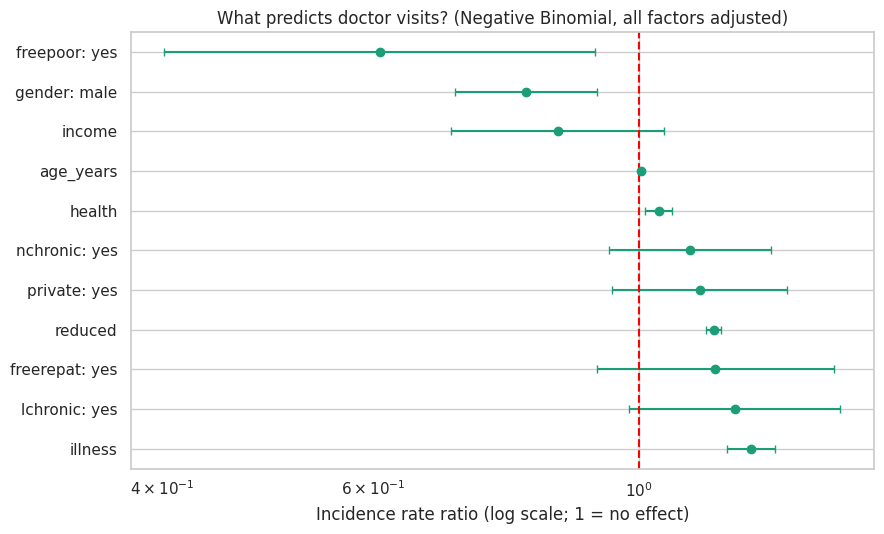

In [42]:
# Incidence Rate Ratios (IRR) with 95% CI from the Negative Binomial model
irr = pd.DataFrame({
    "IRR": np.exp(nb.params),
    "CI low": np.exp(nb.conf_int()[0]),
    "CI high": np.exp(nb.conf_int()[1]),
    "p-value": nb.pvalues}).drop("Intercept")
irr.index = (irr.index.str.replace("C(", "", regex=False).str.replace(")[T.", ": ", regex=False).str.replace("]", "", regex=False))
irr = irr.sort_values("IRR", ascending=False)
display(irr.round(3))

plt.figure(figsize=(9, 5.5))
y = np.arange(len(irr))
plt.errorbar(irr["IRR"], y, xerr=[irr["IRR"]-irr["CI low"], irr["CI high"]-irr["IRR"]], fmt="o", color="#1b9e77", capsize=3)
plt.axvline(1, color="red", ls="--"); plt.yticks(y, irr.index); plt.xscale("log")
plt.xlabel("Incidence rate ratio (log scale; 1 = no effect)"); plt.title("What predicts doctor visits? (Negative Binomial, all factors adjusted)")
plt.tight_layout(); plt.show()

**How to read the table:** an IRR of 1.20 means 20% more visits for that group (or per 1-unit increase), holding everything else equal. Variables whose CI crosses the red line at 1 are not distinguishable from no effect.

**Findings after adjustment:**
- **Health need dominates.** Each extra illness and each extra day of reduced activity raise expected visits significantly (check the table for the exact IRRs). These are the strongest and most certain effects.
- **Gender** (males about 0.80x the visits of females, i.e. females about 1.24x) and **free low-income cover** (about 0.61x) remain statistically significant after adjustment, alongside `illness` (IRR about 1.24 per illness), `reduced` (about 1.16 per day) and `health` (about 1.04 per point).
- **Age, income, private insurance, free age/disability cover and both chronic flags are NOT distinguishable from no effect** here (confidence intervals cross 1). The limiting-chronic flag is borderline (p = 0.08). In the raw data these looked important, but most of their apparent effect runs through current illness and reduced activity. Absence of significance is not proof of no effect, though: with this sample some of these intervals are wide.

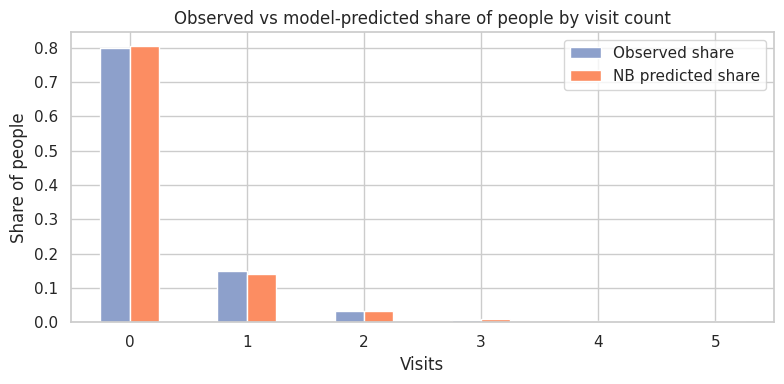

,Observed share,NB predicted share
0,0.798,0.805
1,0.151,0.139
2,0.034,0.032
3,0.006,0.010
4,0.005,0.005
5,0.002,0.003


In [43]:
# Model fit sanity check: observed vs predicted share of each visit count
pred = nb.predict(df)
alpha = best
obs = df["visits"].value_counts(normalize=True).sort_index()
pred_probs = []
for k in range(0, 6):
    n_ = 1/alpha; p_ = n_/(n_ + pred)
    pred_probs.append(stats.nbinom.pmf(k, n_, p_).mean())
cmp = pd.DataFrame({"Observed share": obs.reindex(range(6)).values, "NB predicted share": pred_probs}, index=range(6))
cmp.plot.bar(figsize=(8, 4), color=["#8da0cb", "#fc8d62"], rot=0)
plt.title("Observed vs model-predicted share of people by visit count"); plt.xlabel("Visits"); plt.ylabel("Share of people")
plt.tight_layout(); plt.show()
cmp.round(3)

## 14. Additional Analysis
**Question 1: Who is most likely to visit at all?** Logistic regression on the binary outcome `visited` (any visit vs none).

In [44]:
logit = smf.logit("visited ~ C(gender) + age_years + income + illness + reduced + health + C(private) + C(freepoor) + C(freerepat) + C(lchronic) + C(nchronic)",
                  data=df).fit(disp=False)
orr = pd.DataFrame({"Odds ratio": np.exp(logit.params), "CI low": np.exp(logit.conf_int()[0]),
                    "CI high": np.exp(logit.conf_int()[1]), "p-value": logit.pvalues}).drop("Intercept")
display(orr.sort_values("Odds ratio", ascending=False).round(3))
print(f"Pseudo R-squared: {logit.prsquared:.3f}")

from sklearn.metrics import roc_auc_score
print(f"ROC-AUC (in-sample): {roc_auc_score(df['visited'], logit.predict(df)):.3f}")

,Odds ratio,CI low,CI high,p-value
C(freerepat)[T.yes],1.522,1.158,2.001,0.003
illness,1.305,1.233,1.381,0.000
C(private)[T.yes],1.297,1.065,1.579,0.010
C(lchronic)[T.yes],1.265,0.991,1.615,0.059
reduced,1.171,1.144,1.199,0.000
C(nchronic)[T.yes],1.100,0.920,1.315,0.298
health,1.063,1.028,1.100,0.000
age_years,1.005,1.000,1.010,0.054
income,0.946,0.746,1.199,0.646
C(gender)[T.male],0.771,0.656,0.906,0.002


Pseudo R-squared: 0.127
ROC-AUC (in-sample): 0.757


**Note:** The AUC is about 0.76 and pseudo R-squared about 0.13: the factors help rank who is more likely to visit but cannot reliably predict *who* will visit in a 2-week window. Whether someone visits depends on much that is not in the data (symptom severity, timing, personal habits). The AUC is in-sample, so out-of-sample performance would be equal or lower. Note that for the binary outcome, `freerepat` (OR about 1.5), `private` (about 1.3) and gender are significant, unlike in the count model, so insurance seems to relate more to *whether* people visit than to *how many times*.

**Question 2: Does insurance still matter after accounting for health need?** Compare raw vs adjusted insurance effect.

,Raw ratio vs public-only,Adjusted ratio vs public-only
Free (age/disability/veteran),2.135,1.158
Free (low income),0.722,0.608
Private,1.348,1.124


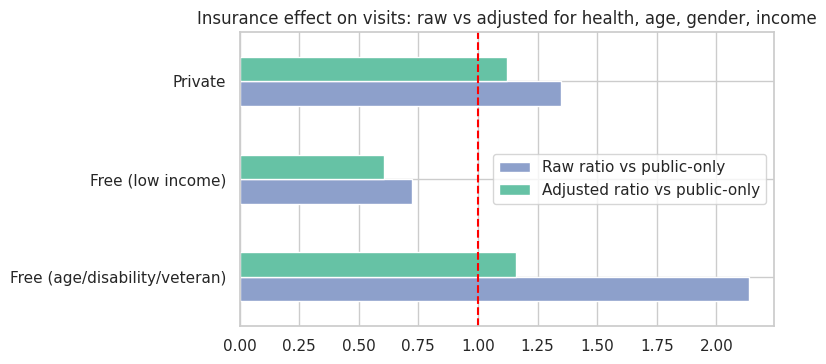

In [45]:
raw = df.groupby("insurance")["visits"].mean()
base = raw["Public only (no extra cover)"]
adj_model = smf.glm("visits ~ C(insurance, Treatment('Public only (no extra cover)')) + age_years + income + C(gender) + illness + reduced + health + C(lchronic) + C(nchronic)",
                    data=df, family=sm.families.NegativeBinomial(alpha=best)).fit()
adj = np.exp(adj_model.params.filter(like="insurance"))
adj.index = [i.split("T.")[1].rstrip("]") for i in adj.index]
comp = pd.DataFrame({"Raw ratio vs public-only": (raw / base).drop("Public only (no extra cover)"),
                     "Adjusted ratio vs public-only": adj})
display(comp.round(3))
comp.plot.barh(figsize=(8, 3.8), color=["#8da0cb", "#66c2a5"])
plt.axvline(1, color="red", ls="--"); plt.title("Insurance effect on visits: raw vs adjusted for health, age, gender, income")
plt.tight_layout(); plt.show()

**Note:** After adjusting for health need, age, gender and income, the raw gap for the "free (age/disability/veteran)" group shrinks from 2.1x to about 1.16x, and private from 1.35x to about 1.12x (both with confidence intervals that include 1 in the count model). The free age/disability group looked like heavy users largely because it is older and sicker. The "free (low income)" group stays low (0.61x), which could reflect eligibility rules or access, and this dataset cannot tell us which.

## 15. Key Insights
1. **Demand is concentrated.** About 80% of people had no visit in the 2 weeks, and the 93 people (1.8%) with 3+ visits account for 27.8% of all visits.
2. **Health need is the strongest driver.** Number of illnesses and days of reduced activity have the strongest correlations with visits and remain the strongest predictors after adjusting for everything else.
3. **Females visit more** (0.36 vs 0.24 mean visits; 24% vs 16% visited at least once), and the difference stays significant after adjustment (about 1.24x), though it fades from age 50 upward.
4. **Visits rise with age** (0.21 for ages 15-24 up to 0.45 for 65+), but the adjusted model shows age has no clear effect once illness is included, so older people mainly visit more because they are sicker.
5. **Raw insurance comparisons mislead.** The free age/disability group looked 2.1x as active as public-only but only about 1.16x after adjustment; private looked 1.35x and shrinks to about 1.12x. Only the free low-income group stays clearly lower.
6. **Income is a weak signal.** Visits are lowest in the top income bands, but the adjusted income effect is not statistically distinguishable from zero.
7. **Data-quality lesson.** 25% of rows are "duplicates" that are really identical banded profiles of healthy people, and dropping them would overstate the visit rate by about 29%.

## 16. Recommendations
- **Target outreach by health need, not demographics alone.** Patients with recent illness or reduced activity are the high-demand group; proactive care for them (chronic-care follow-ups, nurse-led check-ins) is worth piloting for the heavy-user tail, though this data cannot prove it would reduce visits.
- **Plan capacity for older and female patients**, who generate more visits, and for the small high-need group.
- **Do not judge insurance products on raw averages.** Compare like-for-like groups (same age, same health) before concluding that coverage changes visits.
- **For analysts:** use count models (Negative Binomial) instead of ANOVA when the outcome is a skewed count, and check duplicates before dropping them.

## 17. Limitations
- **Old, narrow data:** 1977-78 Australia, single adults only, young and old over-sampled. Do not generalise to today's population or healthcare system.
- **Association, not causation:** illness and visits are measured in the same 2-week window, so sicker people visiting more is partly built in.
- **Banded and capped variables:** age and income are band midpoints; income is top-coded.
- **Short outcome window:** two weeks gives mostly zeros, so individual-level prediction is weak.
- **No ID or date column:** repeat visits or time trends cannot be studied.

## 18. Conclusion
Doctor visits in this dataset are driven mainly by **health need** (current illness and reduced activity), with additional but smaller roles for gender and age. Many apparent effects, especially insurance type and income, shrink once health need is controlled. The analysis shows why EDA should be followed by adjusted, count-appropriate modelling before any business conclusion is drawn.

## 19. Project Checklist
- [x] Data loading and inspection
- [x] Missing value and duplicate analysis (with a justified decision to keep duplicates)
- [x] Feature engineering (age in years, income in AUD, insurance and chronic categories)
- [x] Descriptive statistics
- [x] Univariate, bivariate and multivariate visualisation
- [x] Outlier analysis (justified retention)
- [x] Statistical tests (Mann-Whitney, Kruskal-Wallis, chi-square, bootstrap CIs)
- [x] Count regression (Poisson to Negative Binomial) and logistic regression
- [x] Insights, recommendations and limitations